In [33]:
import numpy as np
from scipy.integrate import odeint
from scipy.optimize import Bounds, NonlinearConstraint, minimize
from scipy.stats import qmc
import matplotlib.pyplot as plt
from numpy import random as rdm
from pathlib import Path
from pathos.multiprocessing import ProcessingPool as Pool 
from os import cpu_count

from Parameter_Estimation_lotka_volterra import Identifiability_Analysis_lotka_volterra
bool_plot = False

In [34]:

class Identifiability_Analysis_lotka_volterra:
    # Parameters (log10 scale): alpha, beta, delta, gamma
    # States: y = [prey, predator]; initial populations are known.

    PARAM_NAMES = ["alpha", "beta", "delta", "gamma"]

    def __init__(
        self,
        n_data_points,
        opt_pm=None,
        sigma=0.1,
        n_pm_search_lattice_points=15,
        observed=(0, 1),
        true_params = (0.52, 0.026, 0.026, 0.84),
        t_end = 20,
        bool_unknown_y0 = False,
        confidence_treshold = 3.87 # 95 percent confidence intervals
    ):
        if (
            not isinstance(n_data_points, (int, np.integer))
            or isinstance(n_data_points, bool)
            or n_data_points < 1
        ):
            raise ValueError("n_data_points must be a positive integer")
        if sigma <= 0:
            raise ValueError("sigma must be positive")
        if not observed or any(index not in (0, 1) for index in observed):
            raise ValueError("observed must contain 0 (prey), 1 (predator), or both")
        if len(set(observed)) != len(observed):
            raise ValueError("observed indices must not be repeated")
        if n_pm_search_lattice_points < 1:
            raise ValueError("n_pm_search_lattice_points must be positive")

        self.n_data_points = n_data_points
        self.sigma_fraction = sigma
        self.n_pm_search_lattice_points = n_pm_search_lattice_points
        self.observed = list(observed)
        self.t_end = t_end

        # Optional: treat the initial populations as unknown (last two parameters)
        self.bool_unknown_y0 = bool_unknown_y0
        self.n_params = 6 if bool_unknown_y0 else 4
        self.PARAM_NAMES = list(type(self).PARAM_NAMES)
        self.y0 = np.array([34.0, 5.9])  # true initial prey and predator populations
        self.true_params = tuple(true_params)  # alpha, beta, delta, gamma
        if bool_unknown_y0:
            self.PARAM_NAMES += ["prey_0", "predator_0"]
            self.true_params += tuple(self.y0)
        self.labels = ["Prey", "Predator"]
        self.colors = ["darkorange", "purple"]
        self.PHI_BOUND_LOWER = -2
        self.PHI_BOUND_UPPER = 0.5
        # Per-parameter log10 bounds; initial populations are searched in [1, 100]
        self.phi_lower = np.full(self.n_params, self.PHI_BOUND_LOWER, dtype=float)
        self.phi_upper = np.full(self.n_params, self.PHI_BOUND_UPPER, dtype=float)
        
        self.phi_lower[4:] = 0.0
        self.phi_upper[4:] = 2.0
        self.threshold_value = confidence_treshold

        self.t_int, self.t_exp, self.states, self.exp_data, self.sigma = (
            self.generate_synthetic_data()
        )

        self.phi_opt = None
        self.cost_opt = None
        if opt_pm is not None:
            self.phi_opt = np.asarray(opt_pm, dtype=float)
            if self.phi_opt.shape != (self.n_params,):
                raise ValueError(f"opt_pm must contain {self.n_params} log10 parameters")
            self.cost_opt = self.optimization_function(self.phi_opt)

        self.ppl_data = {}

    def model(self, y, t, alpha, beta, delta, gamma):
        prey, predator = y
        dprey = alpha * prey - beta * prey * predator
        dpredator = delta * prey * predator - gamma * predator
        return [dprey, dpredator]

    def generate_synthetic_data(self):
        """Generate noisy prey and predator observations at evenly spaced times."""
        t_int = np.linspace(0, self.t_end, 10 * self.t_end + 1)
        t_exp = np.linspace(0, self.t_end, self.n_data_points)
        states = odeint(self.model, self.y0, t_int, args=self.true_params[:4])
        states_at_obs = odeint(self.model, self.y0, t_exp, args=self.true_params[:4])

        observed_data = states_at_obs[:, self.observed]
        noise_sigma = self.sigma_fraction * np.max(observed_data, axis=0)
        rng = rdm.RandomState(4)
        exp_data = observed_data + rng.normal(
            loc=0,
            scale=noise_sigma,
            size=observed_data.shape,
        )
        arr_sigma = np.broadcast_to(noise_sigma, exp_data.shape).copy()
        """
        fig, ax = plt.subplots()
        for data_index, state_index in enumerate(self.observed):
            ax.scatter(
                t_exp,
                exp_data[:, data_index],
                label=f"{self.labels[state_index]} experimental data",
                s=5,
                color=self.colors[state_index],
            )
        ax.set_xlabel("Time")
        ax.set_ylabel("Population")
        ax.legend()
        plt.show()
        """
        return t_int, t_exp, states, exp_data, arr_sigma
    
    def plot_true_trajectory(self):
        fig, ax = plt.subplots()
        for state_index in range(2):
            ax.plot(
                self.t_int,
                self.states[:, state_index],
                label=f"{self.labels[state_index]} true trajectory",
                color=self.colors[state_index],
            )
        ax.set_xlabel("Time")
        ax.set_ylabel("Population")
        ax.legend()
        plt.show()

    def init_phi(self, n_lattice_points=None):
        """Initialize log10-parameter guesses for alpha, beta, delta and gamma."""
        if n_lattice_points is None:
            n_lattice_points = self.n_pm_search_lattice_points
        sampler = qmc.LatinHypercube(d=self.n_params)
        sample = sampler.random(n_lattice_points)
        spacing = self.phi_upper - self.phi_lower
        return [
            sample[i, :] * spacing + self.phi_lower
            for i in range(sample.shape[0])
        ]

    def solve_single(self, phi):
        """Solve the Lotka–Volterra system for one log10 parameter vector."""
        theta = 10 ** np.asarray(phi, dtype=float)
        y0 = theta[4:6] if self.bool_unknown_y0 else self.y0
        states_fit = odeint(self.model, y0, self.t_int, args=tuple(theta[:4]))
        states_at_obs = odeint(self.model, y0, self.t_exp, args=tuple(theta[:4]))
        return states_at_obs, states_fit

    def optimization_function(self, phi):
        """Evaluate the Gaussian -2 log-likelihood for the synthetic data."""
        states_at_obs, _ = self.solve_single(phi)
        residuals = self.exp_data - states_at_obs[:, self.observed]
        sigma_safe = np.maximum(self.sigma, 1e-9)
        minus_2_ll = np.sum(
            np.log(2 * np.pi * sigma_safe**2) + residuals**2 / sigma_safe**2
        )
        return float(minus_2_ll) if np.isfinite(minus_2_ll) else 1e12

    def calibrate_trust_region(self):
        """Multi-start trust-region calibration for all four model parameters."""
        phi_bounds = Bounds(self.phi_lower, self.phi_upper)
        results = []
        print("iteration:")
        for iteration, phi0 in enumerate(self.init_phi()):
            print(iteration)
            results.append(
                minimize(
                    self.optimization_function,
                    phi0,
                    method="trust-constr",
                    bounds=phi_bounds,
                )
            )

        costs = np.array([result.fun for result in results])
        best_idx = np.argmin(costs)
        phi_opt = results[best_idx].x
        cost_opt = costs[best_idx]

        sorted_costs = np.sort(costs)
        fig, ax = plt.subplots()
        ax.plot(np.arange(len(costs)), sorted_costs, lw=1, color="black")
        ax.scatter(np.arange(len(costs)), sorted_costs, s=5, color="red")
        ax.set_xlabel("index")
        ax.set_ylabel("Objective function")
        if np.all(sorted_costs > 0):
            ax.set_yscale("log")
        plt.show()

        print("TR phi_opt:", phi_opt)
        print("TR theta_opt:", 10**phi_opt, " true:", self.true_params)
        print("TR cost_opt:", cost_opt)
        self.phi_opt = np.copy(phi_opt)
        self.cost_opt = float(cost_opt)
        output_dir = self.get_output_dir()
        np.savetxt(output_dir / "phi_opt.txt", phi_opt)
        np.savetxt(output_dir / "cost_opt.txt", [cost_opt])
        return phi_opt, cost_opt

    def plot_result(self, phi_opt=None):
        """Plot fitted population trajectories and the observed data."""
        if phi_opt is None:
            phi_opt = self.phi_opt = np.loadtxt(self.get_output_dir() / "phi_opt.txt")
            self.cost_opt = float(np.loadtxt(self.get_output_dir() / "cost_opt.txt"))
        _, states_fit = self.solve_single(phi_opt)
        print("phi_opt: ", phi_opt)
        fig, ax = plt.subplots()
        for state_index in range(2):
            ax.plot(
                self.t_int,
                states_fit[:, state_index],
                color=self.colors[state_index],
                lw=1,
                label=self.labels[state_index] + " fit",
            )
        for data_index, state_index in enumerate(self.observed):
            ax.errorbar(
                self.t_exp,
                self.exp_data[:, data_index],
                yerr=self.sigma[:, data_index],
                fmt="none",
                color="grey",
                alpha=0.4,
            )
            ax.scatter(
                self.t_exp,
                self.exp_data[:, data_index],
                color=self.colors[state_index],
                s=10,
                label=self.labels[state_index] + " data",
            )
        ax.set_xlabel("Time")
        ax.set_ylabel("Population")
        ax.legend()
        output_dir = self.get_output_dir()
        plt.savefig(output_dir/ "trajectory_fit")
        plt.show()

    def recalibrate_model_simple(self, fixed_val, fixed_index, phi_opt):
        """Re-optimize all other parameters with one parameter fixed."""
        if not 0 <= fixed_index < self.n_params:
            raise ValueError(f"fixed_index must be between 0 and {self.n_params - 1}")
        if fixed_val <= 0:
            raise ValueError("fixed_val must be positive")

        phi_opt = np.asarray(phi_opt, dtype=float)
        phi0 = np.delete(phi_opt, fixed_index)
        fixed_phi = np.log10(fixed_val)
        if not self.phi_lower[fixed_index] <= fixed_phi <= self.phi_upper[fixed_index]:
            raise ValueError("fixed_val must lie within the PHI bounds")

        def objective(phi_free):
            return self.optimization_function(
                np.insert(phi_free, fixed_index, fixed_phi)
            )

        bounds = Bounds(
            np.delete(self.phi_lower, fixed_index),
            np.delete(self.phi_upper, fixed_index),
        )
        result = minimize(objective, phi0, method="trust-constr", bounds=bounds)
        phi_opt_new = np.insert(result.x, fixed_index, fixed_phi)
        return phi_opt_new, result.fun

    def profile_likelihood_simple_(
        self,
        fixed_index,
        n_points=15,
        lower_range=1,
        upper_range=1,
        bool_all_range=False,
        show_plot=False,
    ):
        """Profile one parameter at logarithmically spaced values."""
        if self.phi_opt is None:
            raise ValueError(
                "The parameters have to be estimated first (calibrate_trust_region)"
            )
        if not 0 <= fixed_index < self.n_params:
            raise ValueError(f"fixed_index must be between 0 and {self.n_params - 1}")

        phi_opt = np.asarray(self.phi_opt, dtype=float)
        param_opt = phi_opt[fixed_index]
        if bool_all_range:
            lower_bound = self.phi_lower[fixed_index]
            upper_bound = self.phi_upper[fixed_index]
        else:
            lower_bound = max(param_opt - lower_range, self.phi_lower[fixed_index])
            upper_bound = min(param_opt + upper_range, self.phi_upper[fixed_index])
        if lower_bound >= upper_bound:
            raise ValueError("The requested profile interval does not overlap the PHI bounds")

        fixed_param_values = 10 ** np.linspace(lower_bound, upper_bound, n_points)
        chi_sq_values = []
        print(f"\nComputing profile likelihood for {self.PARAM_NAMES[fixed_index]}...")
        print(f"Bounds (log10): [{lower_bound:.3f}, {upper_bound:.3f}]")

        phi_init = phi_opt
        for fixed_val in fixed_param_values:
            phi_opt_new, chi_sq_val = self.recalibrate_model_simple(
                fixed_val, fixed_index, phi_init
            )
            chi_sq_values.append(chi_sq_val)
            phi_init = phi_opt_new

        ppl_data = np.column_stack((fixed_param_values, chi_sq_values))
        self.ppl_data[fixed_index] = ppl_data.copy()
        output_dir = self.get_output_dir()
        np.savetxt(
            output_dir / f"ppl_data_{self.PARAM_NAMES[fixed_index]}_N_{n_points}_points.txt",
            ppl_data,
        )
        if show_plot:
            self.plot_ppl_data(ppl_data, fixed_index, n_points)
        return ppl_data

    def get_output_dir(self):
        """Single output folder for profile data and figures of this configuration."""
        add_str = "both" if len(self.observed) == 2 else str(self.observed[0])
        if self.bool_unknown_y0:
            add_str += "_y0_unknown"
        output_dir = Path("FiguresProfileLikelihood_lotka_volterra_" + add_str)
        output_dir.mkdir(parents=True, exist_ok=True)
        return output_dir

    def plot_ppl_data(self, ppl_data, fixed_index, n_points, ax=None):
        """Plot profile likelihood with fitted and true parameter values.

        If `ax` is given, draw on it only (no saving/showing); otherwise create,
        save and show a standalone figure.
        """
        if not 0 <= fixed_index < self.n_params:
            raise ValueError(f"fixed_index must be between 0 and {self.n_params - 1}")

        standalone = ax is None
        fixed_param_values = ppl_data[:, 0]
        chi_sq_values = ppl_data[:, 1]
        if standalone:
            fig, ax = plt.subplots()
        ax.axhline(
            y=self.cost_opt + self.threshold_value,
            color="black",
            linestyle="--",
            linewidth=1.5,
            label=f"cost_opt + {self.threshold_value}",
        )
        ax.axvline(
            x=np.asarray(self.phi_opt, dtype=float)[fixed_index],
            color="green",
            linestyle="--",
            linewidth=1.5,
            label="Optimal value",
        )
        ax.axvline(
            x=np.log10(self.true_params[fixed_index]),
            color="blue",
            linestyle=":",
            linewidth=1.5,
            label="True value",
        )
        ax.plot(np.log10(fixed_param_values), chi_sq_values, color="red", linewidth=1.5)
        ax.set_xlabel(f"log10({self.PARAM_NAMES[fixed_index]})", fontsize = 18)
        ax.set_ylabel("Profile likelihood value")
        ax.set_ylim(self.cost_opt - 3, self.cost_opt + self.threshold_value + 10)
        ax.legend()
        ax.grid(True, alpha=0.3)

        if not standalone:
            return
        output_dir = self.get_output_dir()
        plt.savefig(output_dir / f"_n_points_{n_points}_"
            f"fidx_{fixed_index}_sigma_{self.sigma_fraction}_Threshold_{self.threshold_value}.png")
        np.savetxt(
            output_dir / f"ppl_data_{self.PARAM_NAMES[fixed_index]}_N_{n_points}_points.txt",
            ppl_data,
        )
        plt.show()
    
    def extract_confidence_intervals( self, arr_fixed_indices=None, arr_n_points=None ):
        
        if self.cost_opt is None:
            raise ValueError("Calibrate the model before extracting confidence intervals")
        if arr_fixed_indices is None:
            arr_fixed_indices = range(self.n_params)
        if arr_n_points is None:
            arr_n_points = [15] * len(arr_fixed_indices)
        if len(arr_fixed_indices) != len(arr_n_points):
            raise ValueError("arr_fixed_indices and arr_n_points must have the same length")

        output_dir = self.get_output_dir()

        critical_value = self.cost_opt + self.threshold_value
        print(f"Confidence intervals (cost threshold = {critical_value:.4g}), "
            f"data from '{output_dir}'")
        confidence_intervals = {}

        n_plots = len(arr_fixed_indices)
        n_cols = 2
        n_rows = max(1, int(np.ceil(n_plots / n_cols)))
        fig, axs = plt.subplots(n_rows, n_cols, figsize=(15, 5 * n_rows), squeeze=False)
        axs = axs.flatten()
        for ax in axs[n_plots:]:
            ax.set_visible(False)

        for ax, fixed_index, n_points in zip(axs, arr_fixed_indices, arr_n_points):
            name = self.PARAM_NAMES[fixed_index]
            path = output_dir / f"ppl_data_{name}_N_{n_points}_points.txt"
            if not path.exists():
                print(f"{name:>6}: file not found ({path.name})")
                ax.set_visible(False)
                continue

            profile = np.loadtxt(path, ndmin=2)
            profile = profile[np.argsort(profile[:, 0])]
            inside = profile[:, 1] <= critical_value
            values = profile[inside, 0]

            self.plot_ppl_data(profile, fixed_index, n_points, ax=ax)

            if values.size == 0:
                print(f"{name:>6}: no profile points within the confidence threshold")
                continue

            # Refine each bound by interpolating (in log10 of the parameter) between
            # the last point inside and the first point outside the threshold.
            def crossing(p_in, c_in, p_out, c_out):
                frac = (critical_value - c_in) / (c_out - c_in)
                if p_in > 0 and p_out > 0:
                    return 10 ** (np.log10(p_in) + frac * (np.log10(p_out) - np.log10(p_in)))
                return p_in + frac * (p_out - p_in)

            idx = np.flatnonzero(inside)
            i_lo, i_hi = idx[0], idx[-1]
            low, high = float(profile[i_lo, 0]), float(profile[i_hi, 0])
            if i_lo > 0:
                low = float(crossing(*profile[i_lo, :2], *profile[i_lo - 1, :2]))
            if i_hi < len(profile) - 1:
                high = float(crossing(*profile[i_hi, :2], *profile[i_hi + 1, :2]))
            confidence_intervals[name] = (low, high)
            print(
                f"{name:>6}: [{low:.3e}, {high:.3e}]  "
                f"log10: [{np.log10(low):+.2f}, {np.log10(high):+.2f}]  "
                f"span: {np.log10(high) - np.log10(low):.2f} orders of magnitude"
            )

        fig.tight_layout()
        
        output_dir = self.get_output_dir()
        plt.savefig(output_dir / f"All_Profiles")
        plt.show()
        return confidence_intervals
    
    def plot_all_profiles_one_figure( self, arr_fixed_indices=None, arr_n_points=None ):
        colors = ["red", "black", "green", "orange", "purple", "blue"]
        if self.cost_opt is None:
            raise ValueError("Calibrate the model before extracting confidence intervals")
        if arr_fixed_indices is None:
            arr_fixed_indices = range(self.n_params)
        if arr_n_points is None:
            arr_n_points = [15] * len(arr_fixed_indices)
        if len(arr_fixed_indices) != len(arr_n_points):
            raise ValueError("arr_fixed_indices and arr_n_points must have the same length")

        output_dir = self.get_output_dir()

        critical_value = self.cost_opt + self.threshold_value

        fig, ax = plt.subplots(figsize=(10, 6))
        ax.axhline(critical_value, color="black", ls="--", lw=1.5,
                   label=f"cost_opt + {self.threshold_value}")

        for k, (fixed_index, n_points) in enumerate(zip(arr_fixed_indices, arr_n_points)):
            name = self.PARAM_NAMES[fixed_index]
            path = output_dir / f"ppl_data_{name}_N_{n_points}_points.txt"
            if not path.exists():
                print(f"{name:>6}: file not found ({path.name})")
                continue

            profile = np.loadtxt(path, ndmin=2)
            profile = profile[np.argsort(profile[:, 0])]
            log_values = np.log10(profile[:, 0])
            in_bounds = (log_values >= self.phi_lower[fixed_index]) & (
                log_values <= self.phi_upper[fixed_index]
            )
            ax.plot(log_values[in_bounds], profile[in_bounds, 1],
                    color=colors[k % len(colors)], lw=1.5, label=name)

        ax.set_xlim(self.phi_lower.min(), self.phi_upper.max())
        ax.set_ylim(self.cost_opt - 3, critical_value + 10)
        ax.set_xlabel("log10(parameter)", fontsize=14)
        ax.set_ylabel("Profile likelihood value")
        ax.legend()
        ax.grid(True, alpha=0.3)
        fig.tight_layout()
        fig.savefig(output_dir / "All_Profiles_One_Figure.png")
        plt.show()


### Lotka Volterra model:

\begin{align*}
    \frac{dx}{dt} &= \alpha x - \beta y\\
    \frac{dy}{dt} &= -\gamma y + \delta x y .
\end{align*}

with true parameter values choses as: $\alpha = 0.52, \beta = 0.026, \gamma = 0.84, \delta = 0.026$. $x$ is the prey population and $y$ is the predator population.

#### Case 1: Both prey and predator populations are observed

phi_opt:  [-0.29219128 -1.59293696 -1.57723104 -0.06652322]


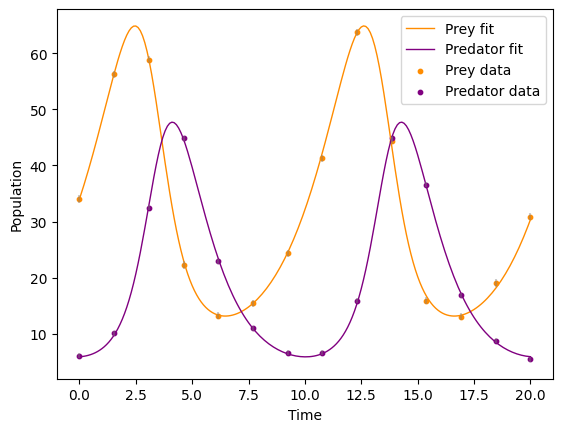

In [11]:
ID_2OBS = Identifiability_Analysis_lotka_volterra(14, sigma = 0.01, n_pm_search_lattice_points=30)
ID_2OBS.plot_result()

In [12]:
ID_2OBS.profile_likelihood_simple_(
        0,
        n_points=15,
        lower_range=0.014,
        upper_range=0.014,
        show_plot=bool_plot)


Computing profile likelihood for alpha...
Bounds (log10): [-0.306, -0.278]


C:\Users\32493\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\scipy\optimize\_differentiable_functions.py:376: UserWarning: delta_grad == 0.0. Check if the approximated function is linear. If the function is linear better results can be obtained by defining the Hessian as zero instead of using quasi-Newton approximations.
  self.H.update(self.x - self.x_prev, self.g - self.g_prev)


array([[ 0.49409302, 44.35759271],
       [ 0.49637365, 41.67999788],
       [ 0.4986648 , 39.40150814],
       [ 0.50096654, 37.52683995],
       [ 0.50327889, 36.06064084],
       [ 0.50560192, 35.00758507],
       [ 0.50793567, 34.37232519],
       [ 0.5102802 , 34.15954639],
       [ 0.51263554, 34.37389265],
       [ 0.51500176, 35.02003016],
       [ 0.5173789 , 36.10257822],
       [ 0.51976702, 37.62618323],
       [ 0.52216615, 39.59549326],
       [ 0.52457636, 42.0151264 ],
       [ 0.5269977 , 44.88969456]])

In [13]:
ID_2OBS.profile_likelihood_simple_(
        1,
        n_points=15,
        lower_range=0.014,
        upper_range=0.014,
        show_plot=bool_plot)


Computing profile likelihood for beta...
Bounds (log10): [-1.607, -1.579]


array([[2.47208297e-02, 4.17693428e+01],
       [2.48349359e-02, 3.97591773e+01],
       [2.49495688e-02, 3.80542039e+01],
       [2.50647307e-02, 3.66559400e+01],
       [2.51804243e-02, 3.55658915e+01],
       [2.52966518e-02, 3.47855242e+01],
       [2.54134159e-02, 3.43162769e+01],
       [2.55307189e-02, 3.41595464e+01],
       [2.56485633e-02, 3.43167332e+01],
       [2.57669517e-02, 3.47891760e+01],
       [2.58858866e-02, 3.55781928e+01],
       [2.60053704e-02, 3.66850849e+01],
       [2.61254057e-02, 3.81110835e+01],
       [2.62459951e-02, 3.98574301e+01],
       [2.63671411e-02, 4.19253194e+01]])

In [14]:
ID_2OBS.profile_likelihood_simple_(
        2,
        n_points=15,
        lower_range=0.014,
        upper_range=0.014,
        show_plot=bool_plot)


Computing profile likelihood for delta...
Bounds (log10): [-1.591, -1.563]


array([[2.56312012e-02, 4.50071215e+01],
       [2.57495095e-02, 4.20977663e+01],
       [2.58683638e-02, 3.96504088e+01],
       [2.59877668e-02, 3.76597640e+01],
       [2.61077209e-02, 3.61206020e+01],
       [2.62282286e-02, 3.50276605e+01],
       [2.63492926e-02, 3.43757121e+01],
       [2.64709154e-02, 3.41595464e+01],
       [2.65930996e-02, 3.43739740e+01],
       [2.67158478e-02, 3.50138400e+01],
       [2.68391625e-02, 3.60739525e+01],
       [2.69630465e-02, 3.75492588e+01],
       [2.70875023e-02, 3.94345595e+01],
       [2.72125325e-02, 4.17248802e+01],
       [2.73381398e-02, 4.44151202e+01]])

In [15]:
ID_2OBS.profile_likelihood_simple_(
        3,
        n_points=15,
        lower_range=0.014,
        upper_range=0.014,
        show_plot=bool_plot)


Computing profile likelihood for gamma...
Bounds (log10): [-0.081, -0.053]


array([[ 0.83076229, 44.68195883],
       [ 0.83459692, 41.86641103],
       [ 0.83844924, 39.49492479],
       [ 0.84231935, 37.56354133],
       [ 0.84620732, 36.0683088 ],
       [ 0.85011323, 35.00521183],
       [ 0.85403718, 34.37029689],
       [ 0.85797923, 34.15954639],
       [ 0.86193949, 34.36895502],
       [ 0.86591802, 34.99447287],
       [ 0.86991491, 36.03207301],
       [ 0.87393026, 37.47770572],
       [ 0.87796414, 39.3273122 ],
       [ 0.88201664, 41.57682188],
       [ 0.88608784, 44.22215553]])

Confidence intervals (cost threshold = 38.03), data from 'FiguresProfileLikelihood_lotka_volterra_both'
 alpha: [5.003e-01, 5.203e-01]  log10: [-0.30, -0.28]  span: 0.02 orders of magnitude
  beta: [2.495e-02, 2.612e-02]  log10: [-1.60, -1.58]  span: 0.02 orders of magnitude
 delta: [2.597e-02, 2.699e-02]  log10: [-1.59, -1.57]  span: 0.02 orders of magnitude
 gamma: [8.414e-01, 8.751e-01]  log10: [-0.08, -0.06]  span: 0.02 orders of magnitude


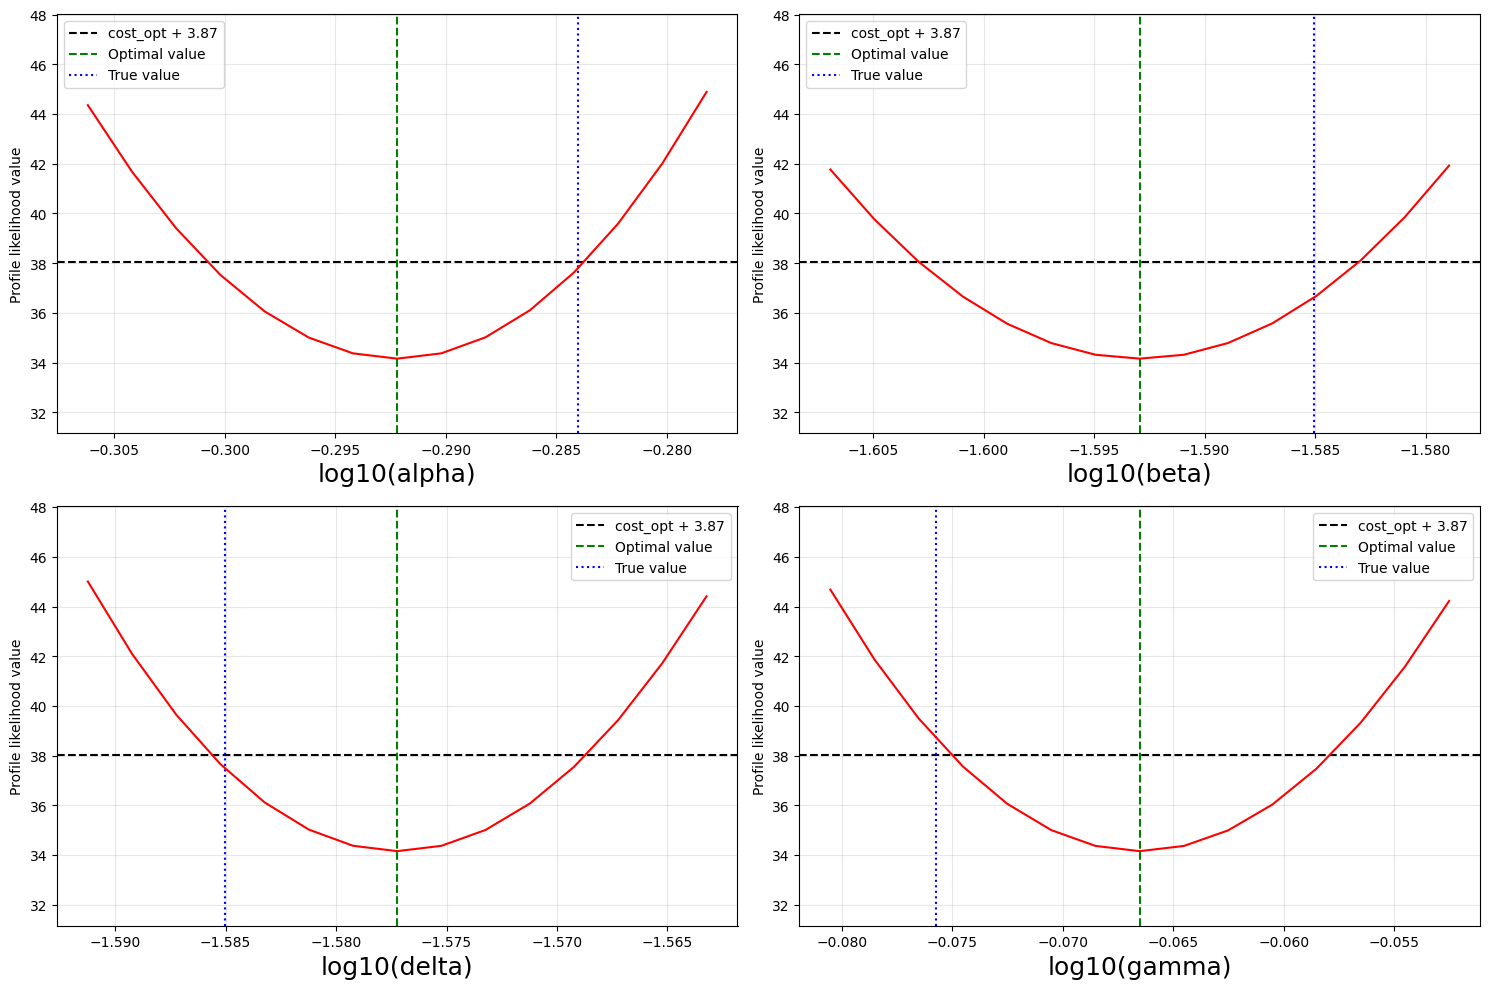

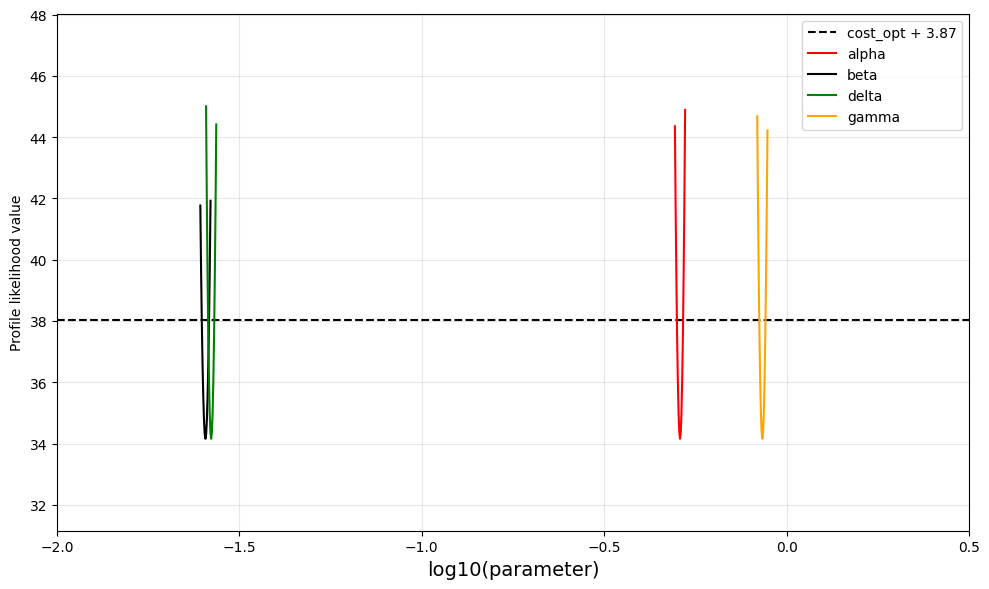

In [12]:
ID_2OBS.extract_confidence_intervals()
ID_2OBS.plot_all_profiles_one_figure()

#### Case 2 (Observable (1,))

phi_opt:  [-0.34974738 -1.64937276 -1.51746371 -0.01604023]


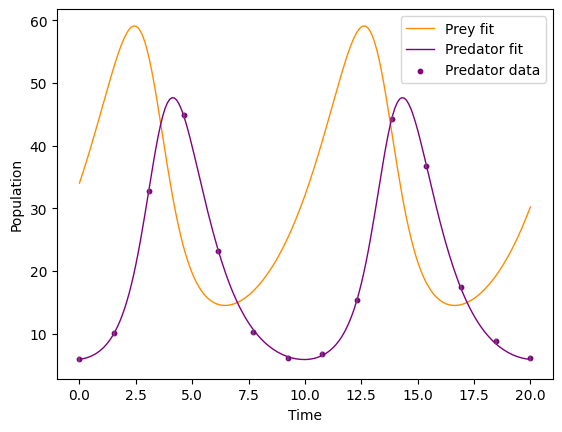

In [28]:

ID_1_OBS = Identifiability_Analysis_lotka_volterra(14, sigma = 0.01, n_pm_search_lattice_points=50, observed = (1,) )

ID_1_OBS.plot_result()

In [17]:
ID_1_OBS.profile_likelihood_simple_(
        0,
        n_points=15,
        lower_range=0.1,
        upper_range=0.1,
        show_plot=bool_plot)


Computing profile likelihood for alpha...
Bounds (log10): [-0.450, -0.250]


array([[ 0.35501984, 12.15805576],
       [ 0.36689208, 10.58397146],
       [ 0.37916134,  9.19806192],
       [ 0.3918409 ,  8.01844554],
       [ 0.40494447,  7.06423224],
       [ 0.41848625,  6.35560492],
       [ 0.43248087,  5.91388939],
       [ 0.44694349,  5.7615536 ],
       [ 0.46188976,  5.92231109],
       [ 0.47733585,  6.42112209],
       [ 0.49329846,  7.28433577],
       [ 0.50979489,  8.53967062],
       [ 0.52684297, 10.21631355],
       [ 0.54446116, 12.34500931],
       [ 0.56266852, 14.95816364]])

In [18]:
ID_1_OBS.profile_likelihood_simple_(
        1,
        n_points=15,
        lower_range=0.1,
        upper_range=0.1,
        show_plot=bool_plot)


Computing profile likelihood for beta...
Bounds (log10): [-1.749, -1.549]


array([[ 0.0178085 , 12.28188066],
       [ 0.01840403, 10.67711882],
       [ 0.01901948,  9.26413665],
       [ 0.01965551,  8.06153251],
       [ 0.02031281,  7.08885764],
       [ 0.0209921 ,  6.36668927],
       [ 0.02169409,  5.91667827],
       [ 0.02241957,  5.7615536 ],
       [ 0.0231693 ,  5.92512908],
       [ 0.02394411,  6.43234927],
       [ 0.02474482,  7.30936208],
       [ 0.02557232,  8.58346473],
       [ 0.02642748, 10.2831523 ],
       [ 0.02731125, 12.43820418],
       [ 0.02822456, 15.07965343]])

In [19]:
ID_1_OBS.profile_likelihood_simple_(
        2,
        n_points=15,
        lower_range=0.1,
        upper_range=0.1,
        show_plot=bool_plot)


Computing profile likelihood for delta...
Bounds (log10): [-1.617, -1.417]


array([[ 0.02412883, 13.76488997],
       [ 0.02493573, 11.57092085],
       [ 0.0257696 ,  9.74478987],
       [ 0.02663137,  8.27696246],
       [ 0.02752195,  7.15680037],
       [ 0.02844231,  6.37269451],
       [ 0.02939345,  5.91209172],
       [ 0.0303764 ,  5.7615536 ],
       [ 0.03139222,  5.90695758],
       [ 0.03244201,  6.33355559],
       [ 0.0335269 ,  7.02608198],
       [ 0.03464808,  7.96889812],
       [ 0.03580675,  9.14613698],
       [ 0.03700416, 10.54178138],
       [ 0.03824162, 12.13980326]])

In [20]:
ID_1_OBS.profile_likelihood_simple_(
        3,
        n_points=15,
        lower_range=0.1,
        upper_range=0.1,
        show_plot=bool_plot)


Computing profile likelihood for gamma...
Bounds (log10): [-0.116, 0.084]


array([[ 0.76552568, 17.19816486],
       [ 0.79112568, 13.85699716],
       [ 0.81758176, 11.1817571 ],
       [ 0.84492257,  9.10825624],
       [ 0.87317768,  7.57884524],
       [ 0.90237767,  6.54173709],
       [ 0.93255414,  5.95011456],
       [ 0.96373974,  5.7615536 ],
       [ 0.99596822,  5.9375339 ],
       [ 1.02927446,  6.44297873],
       [ 1.06369449,  7.24585446],
       [ 1.09926557,  8.31685828],
       [ 1.13602618,  9.62914473],
       [ 1.1740161 , 11.15809953],
       [ 1.21327645, 12.88106961]])

Confidence intervals (cost threshold = 9.632), data from 'FiguresProfileLikelihood_lotka_volterra_1'
 alpha: [3.753e-01, 5.208e-01]  log10: [-0.43, -0.28]  span: 0.14 orders of magnitude
  beta: [1.886e-02, 2.610e-02]  log10: [-1.72, -1.58]  span: 0.14 orders of magnitude
 delta: [2.584e-02, 3.622e-02]  log10: [-1.59, -1.44]  span: 0.15 orders of magnitude
 gamma: [8.379e-01, 1.136e+00]  log10: [-0.08, +0.06]  span: 0.13 orders of magnitude


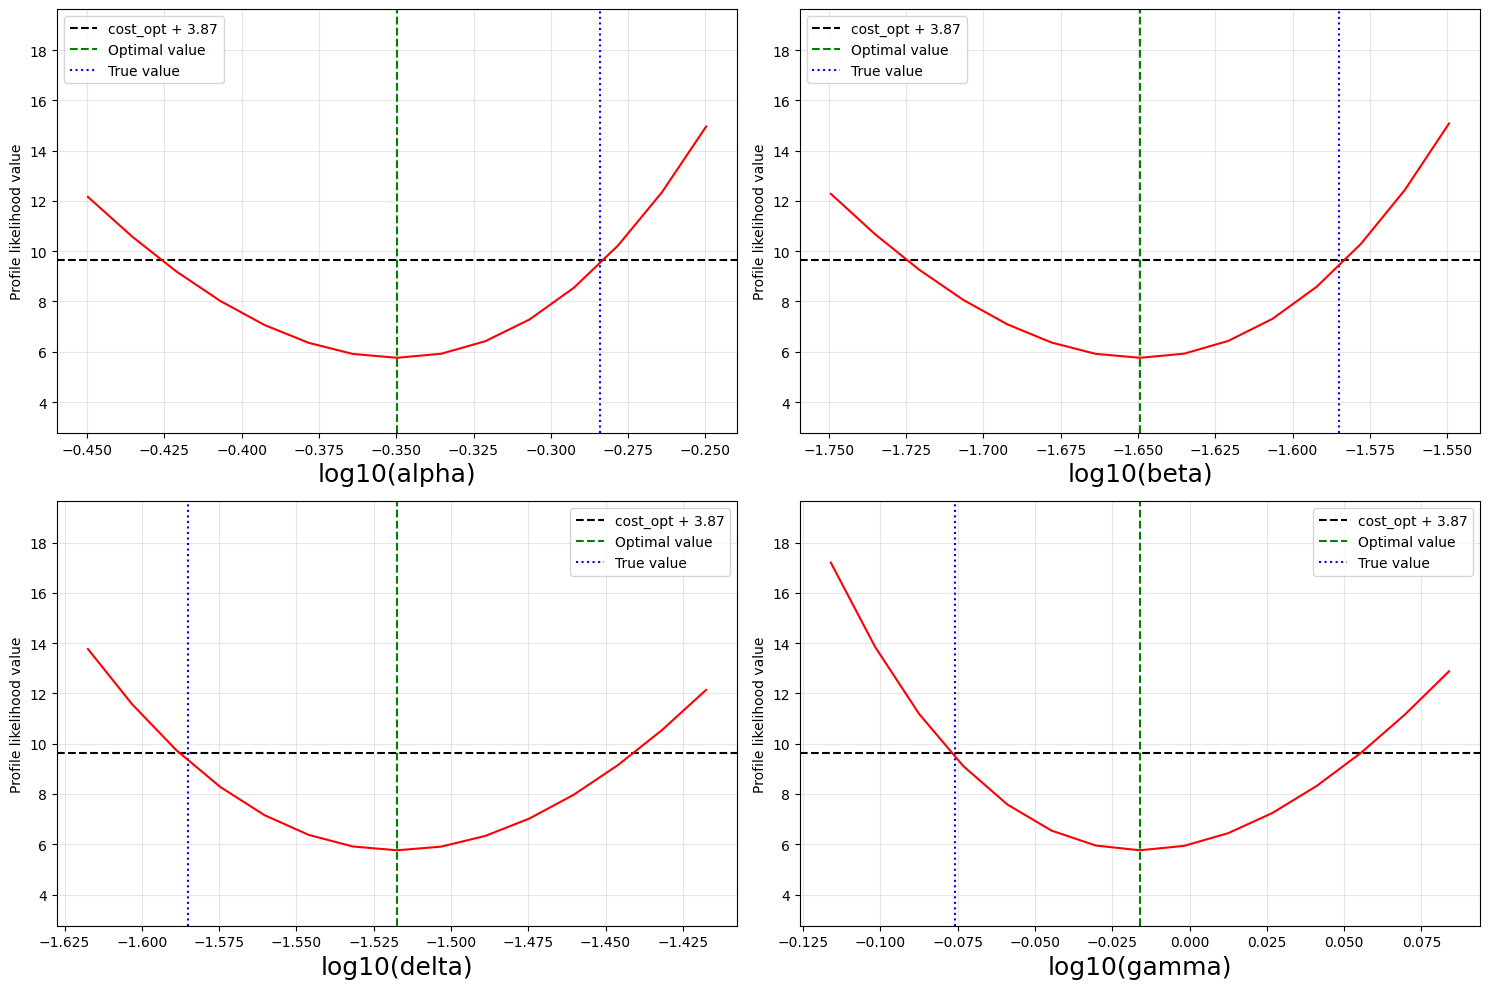

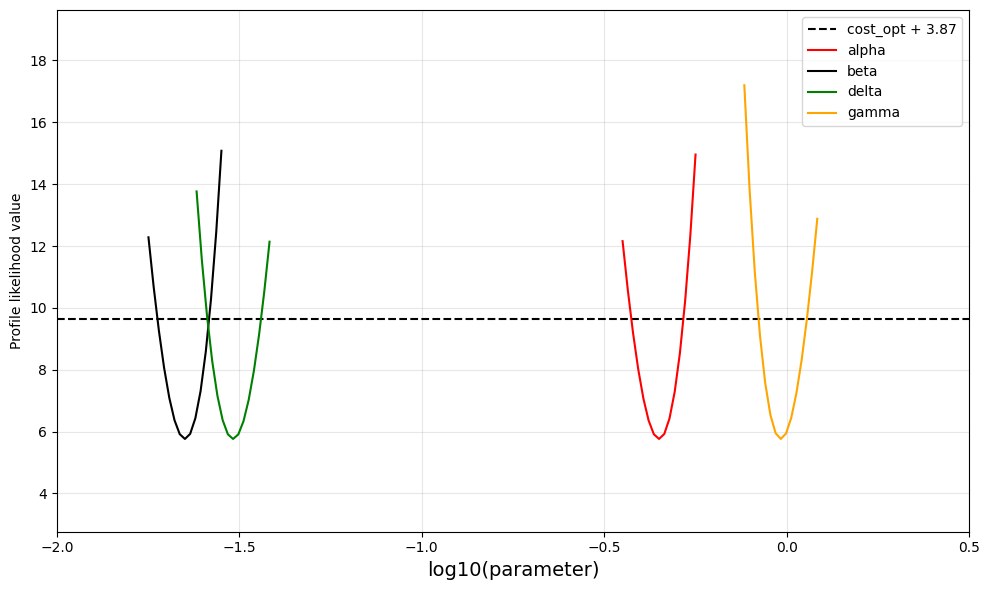

In [15]:
ID_1_OBS.extract_confidence_intervals()
ID_1_OBS.plot_all_profiles_one_figure()

#### (Observable (0,))

phi_opt:  [-0.24298872 -1.48240552 -1.63226448 -0.12286058]


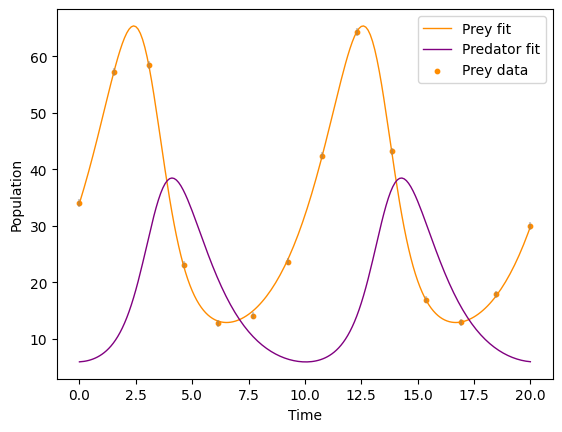

In [29]:
#phi_opt_0_obs = [-0.2429891, -1.48240642, -1.63226404, -0.12286015]

ID_0_OBS = Identifiability_Analysis_lotka_volterra(14, sigma = 0.01, n_pm_search_lattice_points=30, observed = (0,) )
ID_0_OBS.plot_result()

In [23]:
ID_0_OBS.profile_likelihood_simple_(
        0,
        n_points=15,
        lower_range=0.1,
        upper_range=0.1,
        show_plot=bool_plot)


Computing profile likelihood for alpha...
Bounds (log10): [-0.343, -0.143]


array([[ 0.4539534 , 37.37170132],
       [ 0.46913409, 31.12964092],
       [ 0.48482243, 26.17824194],
       [ 0.50103541, 22.38028863],
       [ 0.51779057, 19.6103003 ],
       [ 0.53510603, 17.75414065],
       [ 0.55300055, 16.70821341],
       [ 0.57149348, 16.37881351],
       [ 0.59060483, 16.68137997],
       [ 0.61035528, 17.53971539],
       [ 0.63076621, 18.8852795 ],
       [ 0.6518597 , 20.65652012],
       [ 0.67365858, 22.7982122 ],
       [ 0.69618644, 25.26081203],
       [ 0.71946766, 27.99995851]])

In [24]:
ID_0_OBS.profile_likelihood_simple_(
        1,
        n_points=25,
        lower_range=0.4,
        upper_range=0.4,
        show_plot=bool_plot)


Computing profile likelihood for beta...
Bounds (log10): [-1.882, -1.082]


array([[1.31097521e-02, 6.19022043e+01],
       [1.41555847e-02, 5.45853439e+01],
       [1.52848488e-02, 4.78937127e+01],
       [1.65042001e-02, 4.18377582e+01],
       [1.78208253e-02, 3.64255486e+01],
       [1.92424846e-02, 3.16625828e+01],
       [2.07775569e-02, 2.75516606e+01],
       [2.24350899e-02, 2.40928010e+01],
       [2.42248528e-02, 2.12831655e+01],
       [2.61573944e-02, 1.91170468e+01],
       [2.82441048e-02, 1.75857729e+01],
       [3.04972828e-02, 1.66778325e+01],
       [3.29302085e-02, 1.63788135e+01],
       [3.55572212e-02, 1.66715716e+01],
       [3.83938043e-02, 1.75362577e+01],
       [4.14566763e-02, 1.89504945e+01],
       [4.47638893e-02, 2.08895608e+01],
       [4.83349359e-02, 2.33265433e+01],
       [5.21908632e-02, 2.62325610e+01],
       [5.63543978e-02, 2.95769967e+01],
       [6.08500791e-02, 3.33279015e+01],
       [6.57044040e-02, 3.74518845e+01],
       [7.09459835e-02, 4.19148745e+01],
       [7.66057108e-02, 4.66820306e+01],
       [8.271694

In [25]:
ID_0_OBS.profile_likelihood_simple_(
        2,
        n_points=25,
        lower_range=0.2,
        upper_range=0.2,
        show_plot=bool_plot)


Computing profile likelihood for delta...
Bounds (log10): [-1.832, -1.432]


array([[1.47141616e-02, 4.65744955e+01],
       [1.52898135e-02, 4.26147256e+01],
       [1.58879863e-02, 3.87987115e+01],
       [1.65095609e-02, 3.51558429e+01],
       [1.71554529e-02, 3.17180123e+01],
       [1.78266138e-02, 2.85200116e+01],
       [1.85240320e-02, 2.55994545e+01],
       [1.92487348e-02, 2.29968239e+01],
       [2.00017897e-02, 2.07556228e+01],
       [2.07843057e-02, 1.89223400e+01],
       [2.15974357e-02, 1.75464267e+01],
       [2.24423771e-02, 1.66802117e+01],
       [2.33203746e-02, 1.63788135e+01],
       [2.42327214e-02, 1.66999390e+01],
       [2.51807613e-02, 1.77035984e+01],
       [2.61658907e-02, 1.94518623e+01],
       [2.71895606e-02, 2.20084212e+01],
       [2.82532788e-02, 2.54380929e+01],
       [2.93586122e-02, 2.98063735e+01],
       [3.05071887e-02, 3.51788112e+01],
       [3.17007003e-02, 4.16202568e+01],
       [3.29409047e-02, 4.91941625e+01],
       [3.42296288e-02, 5.79619010e+01],
       [3.55687707e-02, 6.79817868e+01],
       [3.696030

In [26]:
ID_0_OBS.profile_likelihood_simple_(
        3,
        n_points=25,
        lower_range=0.2,
        upper_range=0.2,
        show_plot=bool_plot)


Computing profile likelihood for gamma...
Bounds (log10): [-0.323, 0.077]


array([[ 0.47548784, 47.29922249],
       [ 0.49409002, 43.2708824 ],
       [ 0.51341996, 39.38279805],
       [ 0.53350613, 35.66519859],
       [ 0.55437812, 32.15107294],
       [ 0.57606667, 28.87656785],
       [ 0.59860373, 25.88096075],
       [ 0.62202248, 23.20673483],
       [ 0.64635744, 20.89973114],
       [ 0.67164443, 19.00920908],
       [ 0.69792071, 17.58775143],
       [ 0.72522497, 16.69125487],
       [ 0.75359744, 16.37881351],
       [ 0.78307991, 16.71250899],
       [ 0.8137158 , 17.75707019],
       [ 0.84555024, 19.57960937],
       [ 0.87863011, 22.24910056],
       [ 0.91300415, 25.83576662],
       [ 0.94872297, 30.41057586],
       [ 0.9858392 , 36.04431204],
       [ 1.0244075 , 42.80682908],
       [ 1.06448468, 50.76615013],
       [ 1.10612978, 59.98745613],
       [ 1.14940412, 70.53209547],
       [ 1.19437146, 82.45647395]])

Confidence intervals (cost threshold = 20.25), data from 'FiguresProfileLikelihood_lotka_volterra_0'
 alpha: [5.139e-01, 6.469e-01]  log10: [-0.29, -0.19]  span: 0.10 orders of magnitude
  beta: [2.513e-02, 4.364e-02]  log10: [-1.60, -1.36]  span: 0.24 orders of magnitude
 delta: [2.022e-02, 2.648e-02]  log10: [-1.69, -1.58]  span: 0.12 orders of magnitude
 gamma: [6.550e-01, 8.537e-01]  log10: [-0.18, -0.07]  span: 0.12 orders of magnitude


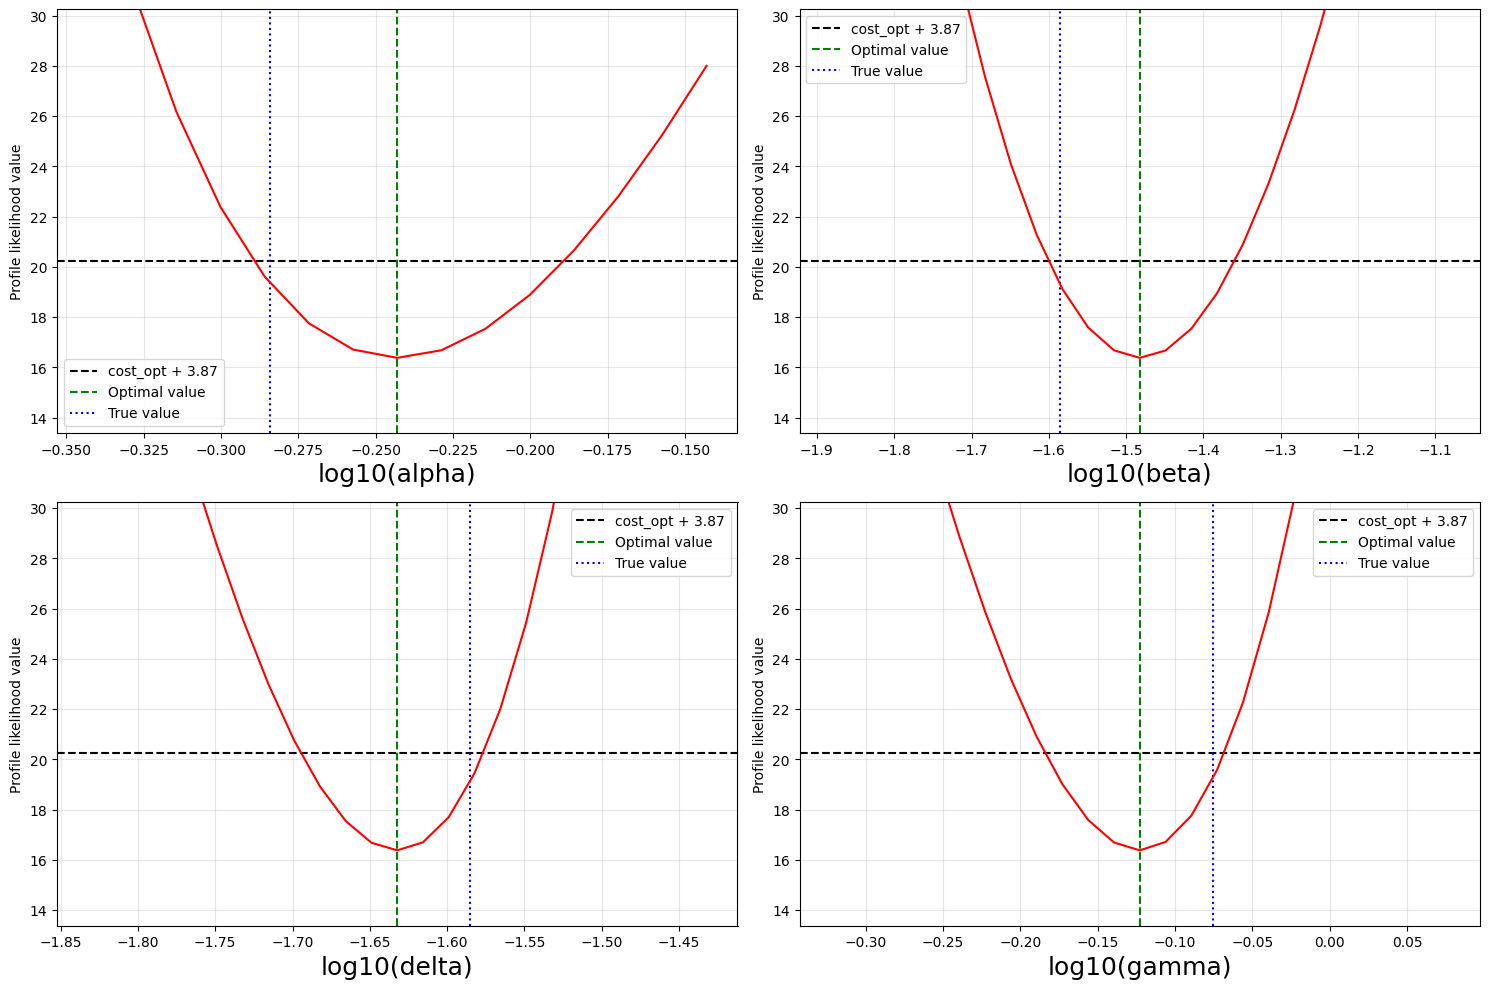

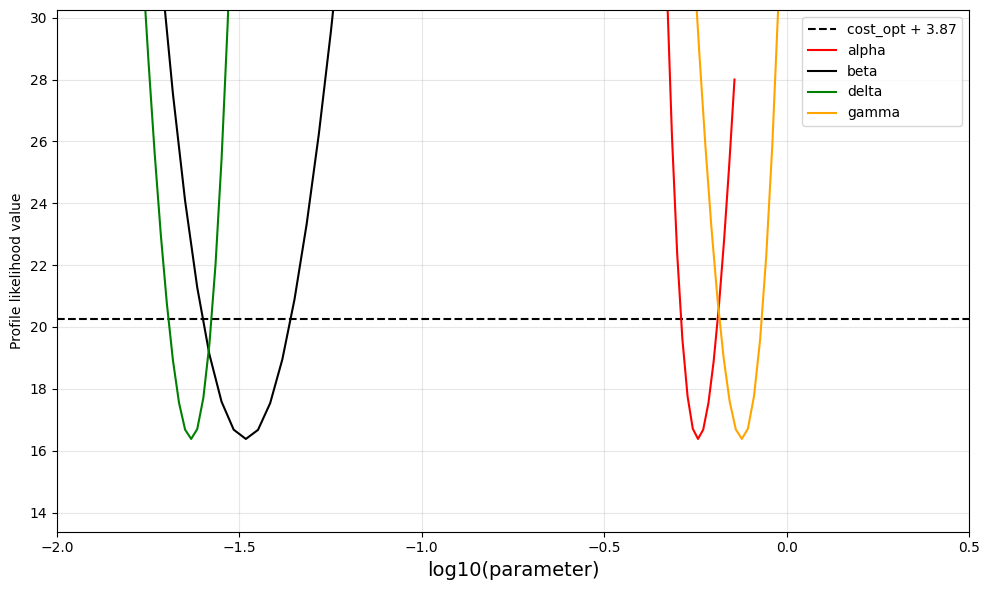

In [32]:
ID_0_OBS.extract_confidence_intervals(arr_n_points=[15,25, 25,25])
ID_0_OBS.plot_all_profiles_one_figure(arr_n_points=[15,25, 25,25])

#### Part 4 $Y_0$ is known, Observable (0,)

phi_opt:  [-0.23450911 -1.17263897 -1.64016458 -0.13138273  1.52837073  0.47908158]


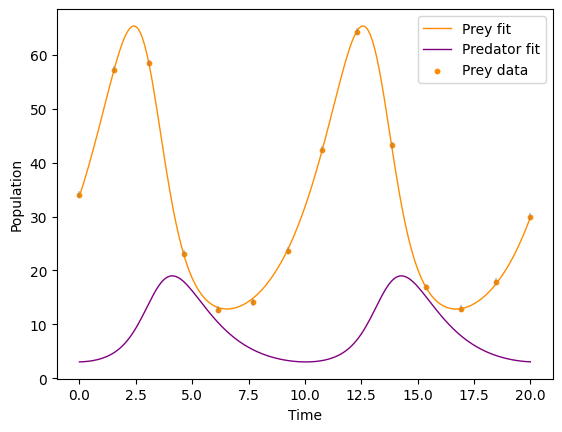

In [35]:
#phi_opt = [-0.23450942, -1.35419216, -1.64016423, -0.13138238, 1.52837075, 0.66063404]
ID_LV_y0_obs_0 = Identifiability_Analysis_lotka_volterra(14, sigma = 0.01, n_pm_search_lattice_points=50, bool_unknown_y0=True, observed=(0,) )
ID_LV_y0_obs_0.plot_result()

In [21]:
ID_LV_y0_obs_0.profile_likelihood_simple_(
        0,
        n_points=50,
        lower_range=0.2,
        upper_range=0.2,
        show_plot=bool_plot)


Computing profile likelihood for alpha...
Bounds (log10): [-0.435, -0.035]


C:\Users\32493\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\scipy\optimize\_differentiable_functions.py:376: UserWarning: delta_grad == 0.0. Check if the approximated function is linear. If the function is linear better results can be obtained by defining the Hessian as zero instead of using quasi-Newton approximations.
  self.H.update(self.x - self.x_prev, self.g - self.g_prev)


KeyboardInterrupt: 

In [37]:
ID_LV_y0_obs_0.profile_likelihood_simple_(
        1,
        n_points=50,
        lower_range = 2,
        upper_range = 0.85,
        show_plot=bool_plot)


Computing profile likelihood for beta...
Bounds (log10): [-2.000, -0.323]


C:\Users\32493\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\scipy\optimize\_differentiable_functions.py:376: UserWarning: delta_grad == 0.0. Check if the approximated function is linear. If the function is linear better results can be obtained by defining the Hessian as zero instead of using quasi-Newton approximations.
  self.H.update(self.x - self.x_prev, self.g - self.g_prev)


array([[1.00000000e-02, 8.28623052e+03],
       [1.08201145e-02, 8.31163713e+03],
       [1.17074878e-02, 8.33774114e+03],
       [1.26676359e-02, 8.36461972e+03],
       [1.37065272e-02, 8.39210006e+03],
       [1.48306194e-02, 8.42016400e+03],
       [1.60469000e-02, 8.44913686e+03],
       [1.73629296e-02, 8.47863519e+03],
       [1.87868887e-02, 8.50890289e+03],
       [2.03276287e-02, 8.53990016e+03],
       [2.19947271e-02, 8.57160710e+03],
       [2.37985466e-02, 8.60400981e+03],
       [2.57502999e-02, 8.63711202e+03],
       [2.78621195e-02, 8.67090024e+03],
       [3.01471324e-02, 8.70540239e+03],
       [3.26195425e-02, 8.74059808e+03],
       [3.52947185e-02, 8.77670458e+03],
       [3.81892897e-02, 8.81368000e+03],
       [4.13212488e-02, 8.85152496e+03],
       [4.47100645e-02, 8.89023261e+03],
       [4.83768018e-02, 8.92978581e+03],
       [5.23442536e-02, 8.97017004e+03],
       [5.66370819e-02, 9.01135659e+03],
       [6.12819713e-02, 9.05330744e+03],
       [6.630779

In [20]:
ID_LV_y0_obs_0.profile_likelihood_simple_(
        2,
        n_points=50,
        lower_range = 0.3,
        upper_range = 0.3,
        show_plot=bool_plot)


Computing profile likelihood for delta...
Bounds (log10): [-1.940, -1.340]


C:\Users\32493\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\scipy\optimize\_differentiable_functions.py:376: UserWarning: delta_grad == 0.0. Check if the approximated function is linear. If the function is linear better results can be obtained by defining the Hessian as zero instead of using quasi-Newton approximations.
  self.H.update(self.x - self.x_prev, self.g - self.g_prev)


array([[1.14771860e-02, 6.08106035e+01],
       [1.18053894e-02, 5.82466731e+01],
       [1.21429782e-02, 5.56884341e+01],
       [1.24902207e-02, 5.31407524e+01],
       [1.28473931e-02, 5.06088370e+01],
       [1.32147792e-02, 4.80984252e+01],
       [1.35926711e-02, 4.56155456e+01],
       [1.39813693e-02, 4.31668237e+01],
       [1.43811827e-02, 4.07593749e+01],
       [1.47924293e-02, 3.84008258e+01],
       [1.52154359e-02, 3.60994137e+01],
       [1.56505389e-02, 3.38638916e+01],
       [1.60980842e-02, 3.17036768e+01],
       [1.65584276e-02, 2.96287944e+01],
       [1.70319350e-02, 2.76500240e+01],
       [1.75189829e-02, 2.57787255e+01],
       [1.80199585e-02, 2.40271112e+01],
       [1.85352601e-02, 2.24080426e+01],
       [1.90652974e-02, 2.09351952e+01],
       [1.96104916e-02, 1.96230176e+01],
       [2.01712763e-02, 1.84867543e+01],
       [2.07480974e-02, 1.75425225e+01],
       [2.13414132e-02, 1.68071940e+01],
       [2.19516957e-02, 1.62984705e+01],
       [2.257942

In [32]:
ID_LV_y0_obs_0.profile_likelihood_simple_(
        3,
        n_points=40,
        lower_range = 0.1,
        upper_range = 0.1,
        show_plot=bool_plot)


Computing profile likelihood for gamma...
Bounds (log10): [-0.231, -0.031]


array([[ 0.58697185, 23.50783707],
       [ 0.59394397, 22.82912668],
       [ 0.60099891, 22.17550695],
       [ 0.60813765, 21.54802831],
       [ 0.61536118, 20.94774301],
       [ 0.62267051, 20.37572588],
       [ 0.63006667, 19.83311414],
       [ 0.63755068, 19.32104659],
       [ 0.64512358, 18.84065048],
       [ 0.65278643, 18.39315604],
       [ 0.66054031, 17.97978129],
       [ 0.66838629, 17.60173233],
       [ 0.67632546, 17.26029896],
       [ 0.68435893, 16.95676833],
       [ 0.69248783, 16.69244805],
       [ 0.70071329, 16.46869409],
       [ 0.70903644, 16.28687466],
       [ 0.71745846, 16.14838144],
       [ 0.72598052, 16.05464127],
       [ 0.7346038 , 16.00709385],
       [ 0.74332951, 16.00719587],
       [ 0.75215887, 16.05646595],
       [ 0.7610931 , 16.15640934],
       [ 0.77013346, 16.3085696 ],
       [ 0.7792812 , 16.51451125],
       [ 0.78853759, 16.775818  ],
       [ 0.79790394, 17.09410269],
       [ 0.80738154, 17.47100886],
       [ 0.81697171,

In [33]:
ID_LV_y0_obs_0.profile_likelihood_simple_(
        4,
        n_points=25,
        lower_range = 0.03,
        upper_range = 0.03,
        show_plot=bool_plot)


Computing profile likelihood for prey_0...
Bounds (log10): [1.498, 1.558]


array([[31.50436525, 47.52300392],
       [31.68624193, 42.71020298],
       [31.8691686 , 38.25949285],
       [32.05315132, 34.18112527],
       [32.23819618, 30.48551251],
       [32.42430932, 27.18321325],
       [32.6114969 , 24.28496662],
       [32.79976513, 21.80164979],
       [32.98912024, 19.74429457],
       [33.17956851, 18.12410621],
       [33.37111625, 16.9524545 ],
       [33.5637698 , 16.24088435],
       [33.75753556, 16.00108906],
       [33.95241994, 16.24498177],
       [34.1484294 , 16.98461793],
       [34.34557043, 18.23228408],
       [34.54384958, 20.00042008],
       [34.7432734 , 22.30167725],
       [34.9438485 , 25.14891433],
       [35.14558154, 28.55518603],
       [35.3484792 , 32.53376854],
       [35.5525482 , 37.09812751],
       [35.7577953 , 42.26191451],
       [35.9642273 , 48.03906513],
       [36.17185105, 54.44365373]])

In [34]:
ID_LV_y0_obs_0.profile_likelihood_simple_(
        5,
        n_points=100,
        lower_range = 1,
        upper_range = 1,
        bool_all_range = False,
        show_plot=bool_plot)


Computing profile likelihood for predator_0...
Bounds (log10): [0.000, 1.479]


array([[ 1.        , 16.00109272],
       [ 1.03499969, 16.00109275],
       [ 1.07122435, 16.00109277],
       [ 1.10871687, 16.00109386],
       [ 1.14752161, 16.00109509],
       [ 1.1876845 , 16.00108994],
       [ 1.22925309, 16.0010925 ],
       [ 1.27227656, 16.00109366],
       [ 1.31680584, 16.00109269],
       [ 1.36289363, 16.00109362],
       [ 1.41059448, 16.0010947 ],
       [ 1.45996484, 16.00109501],
       [ 1.51106315, 16.0010952 ],
       [ 1.56394989, 16.00109758],
       [ 1.61868764, 16.0010909 ],
       [ 1.6753412 , 16.00109086],
       [ 1.73397762, 16.00109669],
       [ 1.79466629, 16.00109479],
       [ 1.85747905, 16.00109499],
       [ 1.92249023, 16.00109262],
       [ 1.98977678, 16.00109256],
       [ 2.05941835, 16.00108904],
       [ 2.13149734, 16.00108955],
       [ 2.20609908, 16.00108876],
       [ 2.28331185, 16.00108906],
       [ 2.36322705, 16.00108902],
       [ 2.44593925, 16.00108898],
       [ 2.53154636, 16.00108892],
       [ 2.62014969,

Confidence intervals (cost threshold = 19.87), data from 'FiguresProfileLikelihood_lotka_volterra_0_y0_unknown'
 alpha: [5.155e-01, 6.738e-01]  log10: [-0.29, -0.17]  span: 0.12 orders of magnitude
  beta: [1.000e-02, 2.748e-01]  log10: [-2.00, -0.56]  span: 1.44 orders of magnitude
 delta: [1.951e-02, 2.635e-02]  log10: [-1.71, -1.58]  span: 0.13 orders of magnitude
 gamma: [6.295e-01, 8.504e-01]  log10: [-0.20, -0.07]  span: 0.13 orders of magnitude
prey_0: [3.298e+01, 3.453e+01]  log10: [+1.52, +1.54]  span: 0.02 orders of magnitude
predator_0: [1.000e+00, 2.779e+01]  log10: [+0.00, +1.44]  span: 1.44 orders of magnitude


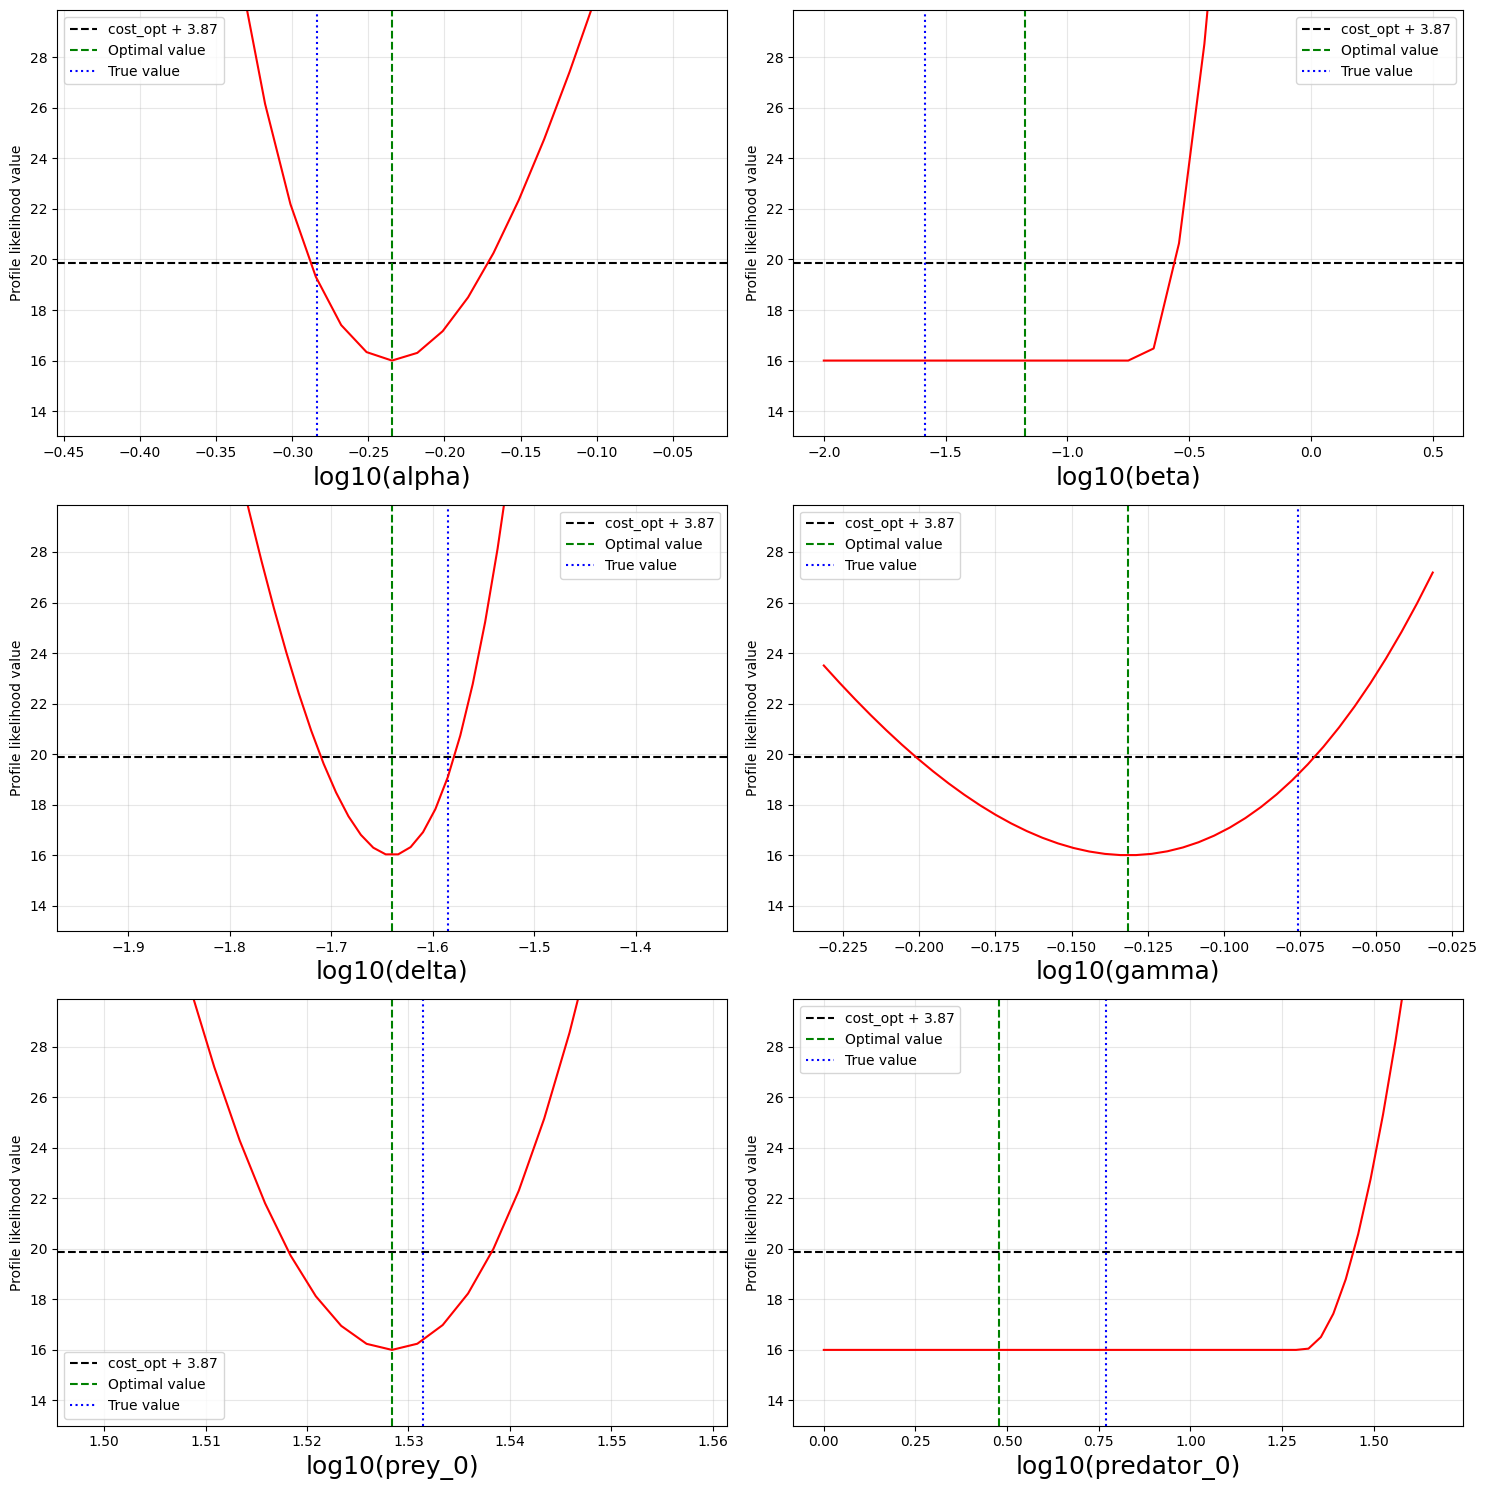

{'alpha': (0.5155434840204849, 0.6738054220101157),
 'beta': (0.01, 0.27481027898428295),
 'delta': (0.0195062390842199, 0.026345515286352632),
 'gamma': (0.6295461980547508, 0.850365685718574),
 'prey_0': (32.977418764408554, 34.52930764963753),
 'predator_0': (1.0, 27.785085588460333)}

In [26]:
ID_LV_y0_obs_0.extract_confidence_intervals(arr_n_points=[25,25, 50, 40, 25, 50 ])


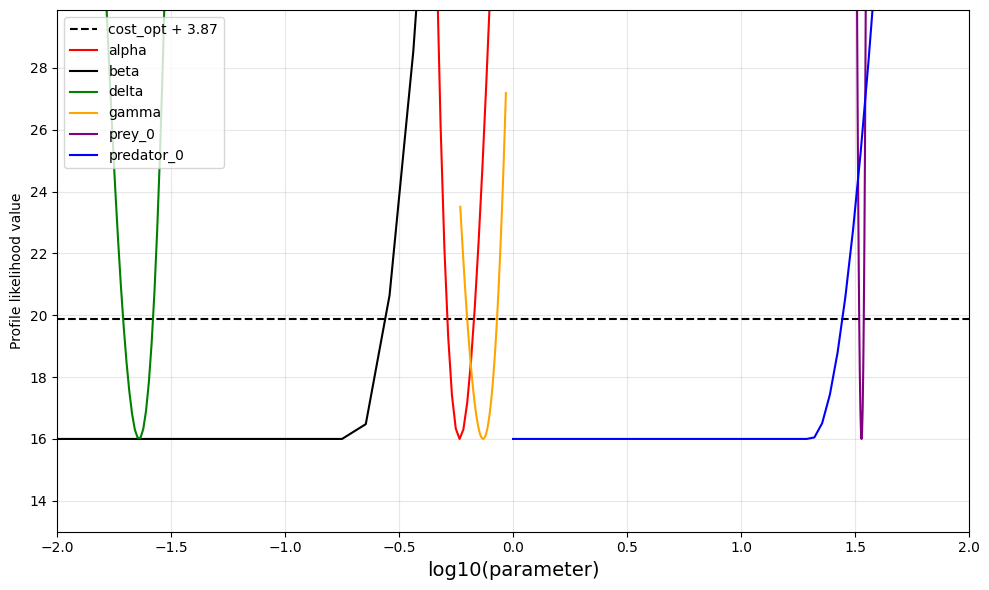

In [27]:
ID_LV_y0_obs_0.plot_all_profiles_one_figure(arr_n_points=[25,25, 50, 40, 25, 50 ])